---
execute:
  skip: true
authors:
- name: Monika Doerig
doi: 10.5281/zenodo.18740130
github: https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb
edit_url: https://github.dev/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb
downloads:
- url: /edu/_sources/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb
  title: Download source notebook
  filename: AFNI_preprocessing_plus_glm_group.ipynb
  static: false
---
# AFNI Preprocessing & Group Analysis

:::{admonition} Reviewed
:class: nd-review-badge nd-review-badge--reviewed

[review issue](<https://github.com/neurodesk/neurodeskedu-reviews/issues/9>) · [@mrneont](<https://github.com/mrneont>)
:::

:::{dropdown} Run this notebook
:class: nd-launch

- [Run in Australia](<https://play.neurodesk.cloud.edu.au/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb&branch=main>)
- [Run in Europe](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb&branch=main>)
- [Run in America](<https://play-america.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb&branch=main>)
- [Run in Global Server 1](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb&branch=main>)
- [Run in Global Server 2](<https://edu.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/AFNI_preprocessing_plus_glm_group.ipynb&branch=main>)
:::



**Date:** May 1 2025

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** If this notebook uses neuroimaging tools from Neurocontainers, those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

### Citation:

#### Tools included in this workflow
__AFNI__
- Cox RW (1996). AFNI: software for analysis and visualization of functional magnetic resonance neuroimages. Comput Biomed Res 29(3):162-173. [doi:10.1006/cbmr.1996.0014](https://pubmed.ncbi.nlm.nih.gov/8812068/)

- RW Cox, JS Hyde (1997). Software tools for analysis and visualization of FMRI Data. NMR in Biomedicine, 10: 171-178., [https://pubmed.ncbi.nlm.nih.gov/9430344/](https://pubmed.ncbi.nlm.nih.gov/9430344/)

#### Workflows this work is based on
- [AFNI Preprocessing](https://neurodesk.org/edu/examples/functional_imaging/AFNI_preprocessing_only.html)
- [AFNI Preprocessing and GLM](https://neurodesk.org/edu/examples/functional_imaging/AFNI_preprocessing_plus_glm.html)


#### Educational resources
__Andy's Brain Book__:

- This AFNI example is based on the [AFNI Tutorial: Statistics and Modeling](https://andysbrainbook.readthedocs.io/en/latest/AFNI/AFNI_Short_Course/AFNI_05_1stLevelAnalysis.html)  from Andy’s Brain Book (Jahn, 2022. [doi:10.5281/zenodo.5879293](https://zenodo.org/records/5879294))

#### Dataset
__Flanker Dataset from OpenNeuro:__
- Kelly AMC and Uddin LQ and Biswal BB and Castellanos FX and Milham MP (2018). Flanker task (event-related). [OpenNeuro Dataset ds000102](https://openneuro.org/datasets/ds000102/versions/00001/). [Dataset] doi: null
- Kelly AM, Uddin LQ, Biswal BB, Castellanos FX, Milham MP. Competition between functional brain networks mediates behavioral variability. Neuroimage. 2008 Jan 1;39(1):527-37. doi: [10.1016/j.neuroimage.2007.08.008](https://doi.org/10.1016/j.neuroimage.2007.08.008). Epub 2007 Aug 23. PMID: 17919929.
- Mennes, M., Kelly, C., Zuo, X.N., Di Martino, A., Biswal, B.B., Castellanos, F.X., Milham, M.P. (2010). Inter-individual differences in resting-state functional connectivity predict task-induced BOLD activity. Neuroimage, 50(4):1690-701. doi: [10.1016/j.neuroimage.2010.01.002](https://doi.org/10.1016/j.neuroimage.2010.01.002). Epub 2010 Jan 15. Erratum in: Neuroimage. 2011 Mar 1;55(1):434
- Mennes, M., Zuo, X.N., Kelly, C., Di Martino, A., Zang, Y.F., Biswal, B., Castellanos, F.X., Milham, M.P. (2011). Linking inter-individual differences in neural activation and behavior to intrinsic brain dynamics. Neuroimage, 54(4):2950-9. doi: [10.1016/j.neuroimage.2010.10.046](https://doi.org/10.1016/j.neuroimage.2010.10.046)ed in your example

### Load packages

In [1]:
import module
await module.load('afni/25.2.03') 
await module.list()

['afni/25.2.03']

### Import Python Modules

In [2]:
%%capture
! pip install nibabel numpy nilearn==0.13.1 scipy

In [3]:
import os
from glob import glob
import subprocess
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from nilearn import image, plotting
from ipyniivue import NiiVue
from IPython.display import display, Markdown, Image
from scipy.stats import ttest_1samp
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from tqdm.notebook import tqdm 

## 1. Download Data

In [4]:
# 9 subjects from the Flanker Dataset
#PATTERN = "sub-0*"
# 3 subjects from the Flanker Dataset for runtime reasons
PATTERN = "sub-0[1-3]"

In [5]:
%%bash -s "$PATTERN"
set -euo pipefail
# Retry transient network failures, then fail the cell instead of continuing without data.
retry() { for i in 1 2 3 4 5; do "$@" && return 0; echo "Attempt $i failed: $*" >&2; [ "$i" -lt 5 ] && sleep $((i * 15)); done; return 1; }
PATTERN=$1
[ -d ds000102 ] || retry datalad install https://github.com/OpenNeuroDatasets/ds000102.git
cd ds000102 && retry datalad get $PATTERN

action summary:
  get (notneeded: 3)


The data is structured in BIDS format:

In [6]:
!tree -L 4 ds000102

ds000102
├── CHANGES
├── README
├── T1w.json
├── dataset_description.json
├── derivatives
│   └── mriqc
│       ├── aMRIQC.csv -> ../../.git/annex/objects/Q4/jv/MD5E-s14180--3addf0456b803b7c5ec5147481ecdd62.csv/MD5E-s14180--3addf0456b803b7c5ec5147481ecdd62.csv
│       ├── anatomical_group.pdf -> ../../.git/annex/objects/6m/q9/MD5E-s98927--d11151f65ae061833e7fd4373adfec3f.pdf/MD5E-s98927--d11151f65ae061833e7fd4373adfec3f.pdf
│       ├── anatomical_sub-01.pdf -> ../../.git/annex/objects/K3/7x/MD5E-s2747349--5d40f2a54fb4194ac4a79f0295ff51c0.pdf/MD5E-s2747349--5d40f2a54fb4194ac4a79f0295ff51c0.pdf
│       ├── anatomical_sub-02.pdf -> ../../.git/annex/objects/Kx/Kv/MD5E-s2803965--56f6b768362bd9b7f0ef501b8cb6dde6.pdf/MD5E-s2803965--56f6b768362bd9b7f0ef501b8cb6dde6.pdf
│       ├── anatomical_sub-03.pdf -> ../../.git/annex/objects/kx/g5/MD5E-s2809843--e90d7a4859ed4be986b55e23f93ca89d.pdf/MD5E-s2809843--e90d7a4859ed4be986b55e23f93ca89d.pdf
│       ├── anatomical_sub-04.pdf -> ../../.git/annex/ob

### Creating Timing Files

Condition-specific timing files are generated using the same approach described in the [*Preprocessing and GLM*](https://neurodesk.org/edu/examples/functional_imaging/AFNI_preprocessing_plus_glm.html) notebook. In brief:

- Onset times and durations are extracted from each subject’s `events.tsv` file.  
- Trials are categorized into **congruent** and **incongruent** conditions.  
- The `make_Timings.sh` script (from Andy’s [AFNI_Scripts repository](https://github.com/andrewjahn/AFNI_Scripts)) is used to convert this event information into AFNI-compatible `.1D` timing files.  
- For each subject, two timing files are created (one per condition), spanning both runs, and saved in the subject’s `func/` directory.  

These `.1D` timing files will then be used in the first-level GLM to model condition-specific brain responses.

In [7]:
![ -f ds000102/make_Timings.sh ] || wget -O ds000102/make_Timings.sh https://raw.githubusercontent.com/andrewjahn/AFNI_Scripts/master/make_Timings.sh

#### Running the Timing File Script
After placing the `make_Timings.sh` script into the `ds000102/` directory, we can execute it from within the notebook:

In [8]:
!cd ds000102 && chmod +x make_Timings.sh && bash make_Timings.sh

Check the output:

In [9]:
!cat ds000102/sub-01/func/incongruent.1D

0 10 40 76 102 150 164 174 208 220 232 260 
0 54 64 76 88 130 144 154 196 246 274 


## 2. Running Preprocessing and First-Level Analysis for All Subjects

All of the preprocessing and regression steps for subject `sub-08` were introduced and explained in the example notebooks [Preprocessing with AFNI](https://neurodesk.org/edu/examples/functional_imaging/AFNI_preprocessing_only.html) and [AFNI Preprocessing and GLM](https://neurodesk.org/edu/examples/functional_imaging/AFNI_preprocessing_plus_glm.html), both of which are highly inspired by [Andy's Brain Book’s tutorial](https://andysbrainbook.readthedocs.io/en/latest/AFNI/AFNI_Short_Course/AFNI_04_Preprocessing.html).  
These notebooks demonstrate how to use `afni_proc.py` to generate an automated pipeline and interpret each preprocessing and regression block.


<div style="background-color: #15803d; padding: 12px; border-left: 6px solid #22c55e; margin: 10px 0; font-size: 16px; color: #f0fdf4;">
    <b style="color: #dcfce7;">Preprocessing and GLM Workflow:</b><br><br>
➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">setup</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">tcat</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">tshift</code>
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">align</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">tlrc</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">volreg</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">blur</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">mask</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">scale</code> 
    ➡️ <code style="background-color: #166534; color: #bbf7d0; padding: 2px 6px; border-radius: 3px;">regress</code> 
    ➡️ 🧠<br><br>
    
✅ <b>Outputs:</b> fitted time series, residuals, tSNR maps, beta weights, and statistical maps from the GLM.
</div>

To replicate the preprocessing and GLM steps used for `sub-08` across multiple participants, we loop over all 3 subjects (sub-01 to sub-03) and generate an individualized AFNI pipeline for each one using `afni_proc.py`. This automated approach performs several key operations:

- Loads each subject's anatomical image and both functional runs.
- Specifies the full processing pipeline: slice timing correction, alignment, linear 
  registration to MNI space, motion correction, blurring, masking, scaling, and regression modeling.
- Models two stimulus conditions (congruent and incongruent) using a gamma basis function (GAM).
- Specifies two general linear tests (GLTs): incongruent − congruent and congruent − incongruent.
- Censors time points with excessive motion (> 0.3 mm) and outlier volumes (> 5% of voxels), 
  and estimates spatial smoothness for later use in group analysis.
- Uses separate motion parameter regressors per run and saves the full fitted timeseries.
- Runs `3dREMLfit` for improved autocorrelation modeling.

Processing is executed in parallel using a process pool, with up to 3 subjects processed simultaneously. Each subject's script is saved and executed in a controlled logging environment, which captures terminal output into a log file for transparency and troubleshooting.

This block ensures consistent preprocessing and first-level GLM estimation across all subjects in the dataset.

<div style="border-left: 4px solid #f59e0b; background-color: rgba(245, 158, 11, 0.1); padding: 10px 15px; border-radius: 4px; margin: 10px 0;">
⏳ <strong>Note:</strong> This next step will take a while to run (approximately 1 to 3 hours depending on computing resources).
</div>

In [10]:
#The following block automatically configures parallelism based on the available CPUs, 
#dividing them evenly across subjects to avoid overloading the system.
    
n_cpus = os.cpu_count() or 4 # fallback to 4 if undetectable
n_subjects = 3 # sub-01 to sub-03
max_workers = min(n_subjects, n_cpus) # don't spawn more workers than CPUs
jobs_per_subject = max(1, n_cpus // max_workers) # divide CPUs evenly across subjects

print(f"CPUs available: {n_cpus}")
print(f"Parallel subjects: {max_workers}")
print(f"Jobs per subject: {jobs_per_subject}")

CPUs available: 16
Parallel subjects: 3
Jobs per subject: 5


In [11]:
# Create directory for output
os.makedirs("afni_pro_glm", exist_ok=True)

# Main subject processing function
def process_subject(subj_id, jobs=4):
    subj = f"sub-{subj_id:02d}"
    anat = f"./ds000102/{subj}/anat/{subj}_T1w.nii.gz"
    func1 = f"./ds000102/{subj}/func/{subj}_task-flanker_run-1_bold.nii.gz"
    func2 = f"./ds000102/{subj}/func/{subj}_task-flanker_run-2_bold.nii.gz"
    stim1D_c = f"./ds000102/{subj}/func/congruent.1D"
    stim1D_i = f"./ds000102/{subj}/func/incongruent.1D"
    out_dir = f"./afni_pro_glm/{subj}.results"
    script_name = f"./afni_pro_glm/proc.{subj}.tcsh"
    log_file = f"./afni_pro_glm/output.{subj}.log"

    # Skip subject if already processed
    if os.path.exists(out_dir):
        return f"{subj} skipped (already processed)"

    cmd = [
        "afni_proc.py",
        "-subj_id", subj,
        "-script", script_name,
        "-scr_overwrite",
        "-out_dir", out_dir,

        # blocks
        # NB: there is a tshift block here, but no slice timing info to apply
        "-blocks", "tshift", "align", "tlrc", "volreg", "blur", "mask", "scale", "regress",

        "-copy_anat", anat,
        "-dsets", func1, func2,

        # extra QC: radial correlation at tcat and volreg stages
        "-radial_correlate_blocks", "tcat", "volreg",

        "-tcat_remove_first_trs", "0",

        # EPI uniformization before alignment (generally helpful for human fMRI)
        "-align_unifize_epi", "local",

        # EPI-anatomical alignment options
        "-align_opts_aea",
            "-cost", "lpc+ZZ", #cost function more in line with standard starting point (and we note EPI-anatomical overlap is quite low initially)
            "-giant_move",
            "-check_flip",

        "-tlrc_base", "MNI152_2009_template_SSW.nii.gz",
        # option for anatomical-template alignment: -tlrc_opts_at -init_xform AUTO_CENTER .
        # This option is needed because the anatomical volume is very far from center to start with for anatomical-template alignment
        # + because the anatomical also has very poor overlap with the EPI dset, 
        # we might suspect that the T1w dset coordinates are not what they were when acquired.
        "-tlrc_opts_at", "-init_xform", "AUTO_CENTER",

        "-volreg_align_to", "MIN_OUTLIER",
        "-volreg_align_e2a",
        "-volreg_tlrc_warp",

        # extra QC: compute tSNR
        "-volreg_compute_tsnr", "yes",

        # set final voxel size (matching voxel grid)
        "-volreg_warp_dxyz", "3.0",

        # intersection mask of EPI and anat
        "-mask_epi_anat", "yes",

        # blur 5mm for 3x3x4 voxel data
        "-blur_size", "5.0",

        "-regress_stim_times", stim1D_c, stim1D_i,
        "-regress_stim_labels", "congruent", "incongruent",
        "-regress_basis", "GAM",
        
        # FMRI data, analyzing for voxelwise analysis
        # Motion and outlier censoring
        "-regress_censor_motion", "0.3",
        "-regress_censor_outliers", "0.05",   # extra censoring security
        "-regress_motion_per_run",

        "-regress_opts_3dD",
            "-jobs", str(jobs),
            "-gltsym", "SYM: incongruent -congruent", "-glt_label", "1", "incongruent-congruent",
            "-gltsym", "SYM: congruent -incongruent", "-glt_label", "2", "congruent-incongruent",

        "-regress_reml_exec",
        "-regress_compute_fitts",             # save fitted timeseries
        "-regress_make_ideal_sum", "sum_ideal.1D",
        "-regress_est_blur_epits",
        "-regress_est_blur_errts",
        "-regress_run_clustsim", "no",
    ]

    try:
        # Step 1: Create the AFNI processing script
        subprocess.run(cmd, check=True)

        # Step 2: Run the AFNI tcsh script, logging output
        with open(log_file, "w") as logfile:
            proc = subprocess.Popen(
                ["tcsh", "-xef", script_name],
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True
            )
            for line in proc.stdout:
                print(line, end="")     # Stream to console
                logfile.write(line)     # Log to file
            proc.wait()

        return f"{subj} {'done' if proc.returncode == 0 else 'failed'}"
        
    except subprocess.CalledProcessError as e:
        return f"{subj} failed: afni_proc.py error"
    except Exception as e:
        return f"{subj} failed: unexpected error\n{e}"

# ──────────────────────────────────────────────────────────────────────────────
# Main loop to process multiple subjects in parallel
subject_ids = list(range(1, 4))  # sub-01 to sub-03
results = []
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    futures = {
        executor.submit(process_subject, sid, jobs_per_subject): sid
        for sid in subject_ids
    }
    for future in tqdm(as_completed(futures), total=len(futures), desc="Subjects processed"):
        results.append(future.result())

print("\nSummary of results:")
for r in results:
    print(r)


Summary of results:
sub-03 skipped (already processed)
sub-01 skipped (already processed)
sub-02 skipped (already processed)


## 3. Group - Analysis

After estimating the first-level general linear model (GLM) for each subject, we will perform a group-level analysis to assess whether the `Incongruent - Congruent` contrast showed a consistent effect across subjects.

#### Creating a Group Mask
First, we'll create a group-level mask by combining each subject's individual mask using a logical intersection. This ensures that only voxels present in **all** subjects' data are  included in the group analysis:

In [12]:
! 3dmask_tool -input afni_pro_glm/sub-*.results/mask_group+tlrc.HEAD -prefix ./afni_pro_glm/group_mask+tlrc -inter

++ processing 3 input dataset(s), NN=2...
++ padding all datasets by 0 (for dilations)
++ have 3 volumes of input to combine
++ frac 1 over 3 volumes gives min count 3
++ voxel limits: 0 clipped, 71053 survived, 240243 were zero
++ writing result group_mask...
** ERROR: output dataset name 'group_mask' conflicts with existing file
** ERROR: dataset NOT written to disk!


### 3.1 Group-Level Analysis with 3dttest++ 

AFNI’s `3dttest++` performs a voxelwise one-sample t-test across subjects. This tests whether the average contrast estimate (e.g., *Incongruent - Congruent*) is significantly different from zero at each voxel.oxelwise t-scoresariability.

#### Identifying Contrast Sub-Brick

Before running the group-level test, we must determine which sub-brick contains the desired contrast. We use `3dinfo` to inspect the subject-level `stats+tlrc` dataset and find the index of the contrast sub-brick corresponding to *incongruent minus congruent* (e.g., sub-brick **#7**, depending on how GLTs were defined in `afni_proc.py`):

In [13]:
! 3dinfo -verb ./afni_pro_glm/sub-01.results/stats.sub-01+tlrc.BRIK

++ 3dinfo: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]

Dataset File:    stats.sub-01+tlrc
Identifier Code: XYZ_yY8tmeGnoti2_oNAau3rfA  Creation Date: Thu Oct  8 16:36:50 2026
Template Space:  MNI_2009c_asym
Dataset Type:    Func-Bucket (-fbuc)
Byte Order:      LSB_FIRST [this CPU native = LSB_FIRST]
Storage Mode:    BRIK
Storage Space:   16,187,392 (16 million) bytes
Geometry String: "MATRIX(-3,0,0,94.5,0,-3,0,130.5,0,0,3,-76.5):64,76,64"
Data Axes Tilt:  Plumb
Data Axes Orientation:
  first  (x) = Left-to-Right
  second (y) = Posterior-to-Anterior
  third  (z) = Inferior-to-Superior   [-orient LPI]
R-to-L extent:   -94.500 [R] -to-    94.500 [L] -step-     3.000 mm [ 64 voxels]
A-to-P extent:   -94.500 [A] -to-   130.500 [P] -step-     3.000 mm [ 76 voxels]
I-to-S extent:   -76.500 [I] -to-   112.500 [S] -step-     3.000 mm [ 64 voxels]
Number of values stored at each pixel = 13
  -- At sub-brick #0 'Full_Fstat' datum type is float:            0 to       57.6257
     statcode = 

This command lists all sub-bricks with their labels, allowing us to find the relevant contrast parameter estimate:
```javascript
-- At sub-brick #7 'incongruent-congruent_GLT#0_Coef' datum type is float:     -22.0622 to       17.8422
```

Sub-bricks labeled with "Coef" represent contrast (beta) estimates, while "Tstat" or "Fstat" indicate test statistics. For group analysis, we will extract the Coef sub-brick (here: index [7]).

We then automate the `3dttest++` execution with the following steps:

- **Set the base directory** containing all subjects' AFNI result folders.
- Locate sub-brick `[**7]` for each subject (the contrast of interest).
- **Verify dataset existence** to avoid processing missing subjects.
- Construct the `3dttest++` command with:
  - An output prefix for group results,
  - A group brain mask to constrain the analysis,
  - A label for the subject set (`Inc-Con`),
  - Subpaired with their corresponding contrast sub-brick pathssti**mates.
- **Run** the command using `subprocess.run()` to capture and log output.

The resulting dataset (`Flanker_Inc-Con_ttest+tlrc`) contains:

- **Effect size map:** average contrast values across subjects
- **T-statistic map:** voxelwise t-values representing statistical significance

In [14]:
base_dir = os.path.abspath("./afni_pro_glm")

# Get all subject folders
subject_dirs = sorted(glob(os.path.join(base_dir, "sub-*.results")))

# Build paths to sub-brik 7 (e.g. Inc-Con contrast)
set_lines = []
for s in subject_dirs:
    sub_id = os.path.basename(s).replace('.results', '')
    stats_path = os.path.join(s, f"stats.{sub_id}+tlrc[7]")
    if os.path.exists(stats_path.replace('[7]', '.BRIK')) or os.path.exists(stats_path):  # extra check
        set_lines.append(f"{sub_id} {stats_path}")
    else:
        print(f"⚠️  Missing file for subject {sub_id}: {stats_path}")

# Build 3dttest++ command
cmd_list = [
    "3dttest++",
    "-prefix", os.path.join(base_dir, "group_results", "Flanker-Inc-Con_ttest"),
    "-mask", os.path.join(base_dir, "group_mask+tlrc"),
    "-setA", "Inc-Con"
]

# Add subject lines
for line in set_lines:
    cmd_list += line.split()

# Run the command
print("Running 3dttest++...")
print("\n")
print("Command:", " ".join(cmd_list))
result = subprocess.run(cmd_list, capture_output=True, text=True)

# Show output
print(result.stdout)
print(result.stderr)

Running 3dttest++...


Command: 3dttest++ -prefix /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/group_results/Flanker-Inc-Con_ttest -mask /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/group_mask+tlrc -setA Inc-Con sub-01 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-01.results/stats.sub-01+tlrc[7] sub-02 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-02.results/stats.sub-02+tlrc[7] sub-03 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-03.results/stats.sub-03+tlrc[7]

++ 3dttest++: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
++ Authored by: Zhark++
++ 71053 voxels in -mask dataset
++ option -setA :: processing as LONG form (label label dset label dset ...)
++ have 3 volumes corresponding to option '-setA'
++ loading -setA datasets
++ t-testing:0123456789.0123456789.0123456789.0123456789.0123456789.!
++ ---------- End of analyses -- freeing workspaces ---

This code snippet automates running AFNI’s `3dttest++` for a group analysis of the *Incongruent - Congruent* contrast:

- **Set the base directory** where all subjects’ AFNI results are stored.
- **Find all subject result folders** matching the pattern `sub-*.results`.
- **Build a list of dataset paths** pointing to the 7th sub-brick `[7]` (the contrast of interest) in each subject’s stats dataset, verifying file existence and alerting if missing.
- **Construct the `3dttest++` command** with:
  - Output prefix for group results,
  - Group mask to restrict the test to voxels common across subjects,
  - Label for the group set (`Inc-Con`),
  - Subject IDs paired with their corresponding contrast sub-brick paths.
- **Run the command** as a subprocess, capturing and printing AFNI’s output and errors for review.



The resulting output (Flanker_Inc-Con_ttest+tlrc) contains:

- **Effect size map**: average contrast across subjects

- **T-statistic map**: voxelwise t-sores


### 3.2 Performing Group Analysis with 3dMEMA

To account for both the variability within subjects (parameter estimate differences) and the variability across subjects (contrast estimate precision), we will also perform a group-level analysis using AFNI’s `3dMEMA.`

Unlike a simple t-test, `3dMEMA` leverages each subject’s contrast estimate and corresponding t-statistic (or standard error), providing a more accurate mixed-effects model.

The steps we will take are:

- Build a set list containing each subject’s ID along with the paths to their contrast estimate (`_REML+tlrc[7]`) and t-statistic (`_REML+tlrc[8]`) sub-bricks.

- Verify that both files exist for each subject to avoid missing data errors.

- Construct the `3dMEMA` command with an output prefix, the group mask, and the full subject set list.

- Run the command as a subprocess, capturing output for review.

This process will produce a group-level statistical map that balances effect size and reliability, offering a robust inference about the **Incongruent - Congruent** contrast across subjects.

In [15]:
# Build set list: all subjects in one set block
set_list = ["-set", "IncCon"]
for s in subject_dirs:
    sub_id = os.path.basename(s).replace(".results", "")
    coef_path = os.path.join(s, f"stats.{sub_id}_REML+tlrc[7]")
    tstat_path = os.path.join(s, f"stats.{sub_id}_REML+tlrc[8]")

    # Sanity check (optional)
    if os.path.exists(coef_path.replace("[7]", ".HEAD")) and os.path.exists(tstat_path.replace("[8]", ".HEAD")):
        set_list += [sub_id, coef_path, tstat_path]
    else:
        print(f"⚠️ Missing for {sub_id}:\n  {coef_path}\n  {tstat_path}")

# Full 3dMEMA command
cmd_list = [
    "3dMEMA",
    "-prefix", os.path.join(base_dir, "group_results", "Flanker_Inc-Con_MEMA"),
    "-mask", os.path.join(base_dir, "group_mask+tlrc"),
] + set_list

# Print and run
print("Running 3dMEMA...\n")
print("Command:", " ".join(cmd_list), "\n")
result = subprocess.run(cmd_list, capture_output=True, text=True)

print(result.stdout)
print(result.stderr)

Running 3dMEMA...

Command: 3dMEMA -prefix /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/group_results/Flanker_Inc-Con_MEMA -mask /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/group_mask+tlrc -set IncCon sub-01 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-01.results/stats.sub-01_REML+tlrc[7] /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-01.results/stats.sub-01_REML+tlrc[8] sub-02 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-02.results/stats.sub-02_REML+tlrc[7] /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-02.results/stats.sub-02_REML+tlrc[8] sub-03 /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-03.results/stats.sub-03_REML+tlrc[7] /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/sub-03.results/stats.sub-03_REML+tlrc[8] 



** Error: 
   File /home/jovyan/workspace/books/examples/

### 3.3 Visualizing Group-Level Results

Now that we have completed both group analyses — one with `3dttest++` and one with `3dMEMA` — let's visualize the resulting **voxelwise t-statistic maps**.

#### Steps:

1. **Convert AFNI datasets to NIfTI format** using `3dcopy`, to ensure compatibility with Python neuroimaging tools like `nilearn`.

2. **Extract the t-statistic sub-brick** (sub-brick index `[1]`) using `3dTcat`. This gives us:
   - `Inc-Con_Tstat` from the `3dttest++` result  
   - `IncCon_Tstat` from the `3dMEMA` result

3. **Load the statistical maps** into Python using `nilearn.image.load_img()`.

4. **Plot using transparent thresholding** via `nilearn.plotting.plot_stat_map()` with `transparency_range=[1, 3.3]`. Rather than hard thresholding, this approach fades out low t-values and makes voxels above T > 3.3 (≈ p < 0.001) fully opaque, giving a more complete and informative view of the data.

   > **Note on Multiple Comparison Correction:**  
   > Cluster-size correction using `3dClustSim` requires stable estimates of spatial smoothness, which generally requires at least 14 subjects.  
   > Since our analysis includes only 3 subjects, we do not apply `3dClustSim` or other parametric corrections.  
   > This approach is intended for **exploratory visualization only** and should not be used for formal statistical inference.

This allows us to visually inspect and compare the **sensitivity** and **spatial extent** of effects revealed by the simple one-sample t-test (`3dttest++`) and the mixed-effects model (`3dMEMA`) for the *Incongruent - Congruent* contrast.

In [16]:
! 3dcopy ./afni_pro_glm/group_results/Flanker-Inc-Con_ttest+tlrc ./afni_pro_glm/group_results/Flanker-Inc-Con_ttest.nii.gz
! 3dcopy ./afni_pro_glm/group_results/Flanker_Inc-Con_MEMA+tlrc ./afni_pro_glm/group_results/Flanker_Inc-Con_MEMA.nii.gz

++ 3dcopy: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
** ERROR: output dataset name 'Flanker-Inc-Con_ttest.nii.gz' conflicts with existing file
** ERROR: dataset NOT written to disk!
++ 3dcopy: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
** ERROR: output dataset name 'Flanker_Inc-Con_MEMA.nii.gz' conflicts with existing file
** ERROR: dataset NOT written to disk!


In [17]:
! 3dinfo -verb ./afni_pro_glm/group_results/Flanker-Inc-Con_ttest.nii.gz

++ 3dinfo: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]

Dataset File:    /home/jovyan/workspace/books/examples/functional_imaging/afni_pro_glm/group_results/Flanker-Inc-Con_ttest.nii.gz
Identifier Code: XYZ_xFmFbaZafNe4EdgefzOIFw  Creation Date: Thu Oct  8 17:00:50 2026
Template Space:  MNI_2009c_asym
Dataset Type:    Anat Bucket (-abuc)
Byte Order:      LSB_FIRST {assumed} [this CPU native = LSB_FIRST]
Storage Mode:    NIFTI
Storage Space:   2,490,368 (2.5 million) bytes
Geometry String: "MATRIX(-3,0,0,94.5,0,-3,0,130.5,0,0,3,-76.5):64,76,64"
Data Axes Tilt:  Plumb
Data Axes Orientation:
  first  (x) = Left-to-Right
  second (y) = Posterior-to-Anterior
  third  (z) = Inferior-to-Superior   [-orient LPI]
R-to-L extent:   -94.500 [R] -to-    94.500 [L] -step-     3.000 mm [ 64 voxels]
A-to-P extent:   -94.500 [A] -to-   130.500 [P] -step-     3.000 mm [ 76 voxels]
I-to-S extent:   -76.500 [I] -to-   112.500 [S] -step-     3.000 mm [ 64 voxels]
Number of values stored at each pixel 

In [18]:
# Copy sub-brik 1 (T-statistic) for ttest++
!3dTcat -prefix ./afni_pro_glm/group_results/Flanker-Inc-Con_ttest_Tstat.nii.gz './afni_pro_glm/group_results/Flanker-Inc-Con_ttest+tlrc[1]'

# Copy sub-brik 1 (T-statistic) for MEMA
!3dTcat -prefix ./afni_pro_glm/group_results/Flanker_Inc-Con_MEMA_Tstat.nii.gz './afni_pro_glm/group_results/Flanker_Inc-Con_MEMA+tlrc[1]'

++ 3dTcat: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
** ERROR: output dataset name 'Flanker-Inc-Con_ttest_Tstat.nii.gz' conflicts with existing file
** ERROR: dataset NOT written to disk!
++ elapsed time = 0.2 s
++ 3dTcat: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
** ERROR: output dataset name 'Flanker_Inc-Con_MEMA_Tstat.nii.gz' conflicts with existing file
** ERROR: dataset NOT written to disk!
++ elapsed time = 0.3 s


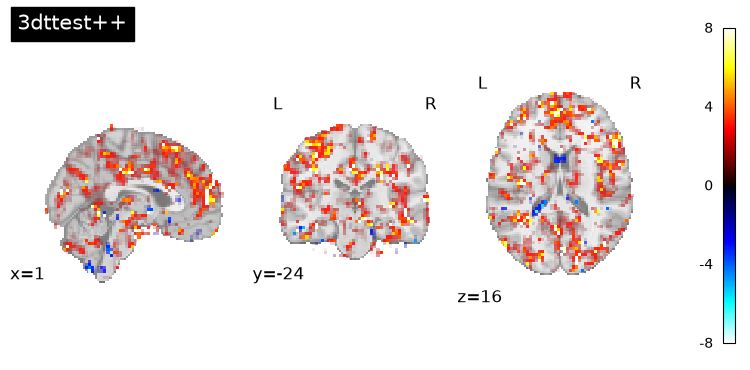

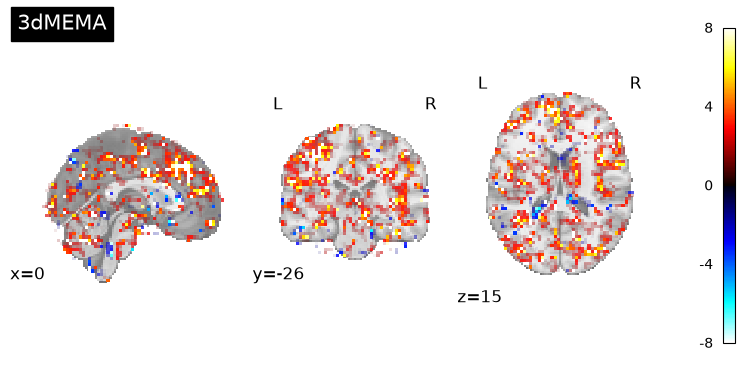

In [19]:
# Load T-stat maps
img_ttest = image.load_img("./afni_pro_glm/group_results/Flanker-Inc-Con_ttest_Tstat.nii.gz")
img_mema = image.load_img("./afni_pro_glm/group_results/Flanker_Inc-Con_MEMA_Tstat.nii.gz")

plotting_config = {
    "display_mode": "ortho",
    "draw_cross": False,
    "vmax": 8,
    "cmap": "cold_hot",
    "colorbar": True,
}
# transparency_range fades voxels with t < 1 to transparent
# and makes voxels with t > 3.3 (p<0.001) fully opaque
for img, title in [
    (img_ttest, "3dttest++"),
    (img_mema, "3dMEMA"),
]:
    plotting.plot_stat_map(
        img,
        title=title,
        transparency=img,
        transparency_range=[1, 3.3],
        **plotting_config,
    )

plotting.show()

## 4. ROI Analysis

### 4.1 ROI Analysis: Atlas-Based MidACC Mask

To investigate group-level effects within a specific anatomical region, we use an atlas-based Region of Interest (ROI) mask focusing on the **mid anterior cingulate cortex (midACC)**.


**1. Identify Available Atlases:**

We begin by confirming the available atlases using:
```bash
!whereami -show_atlas_code
```

This lists all atlases bundled with AFNI.

In [20]:
! whereami -show_atlas_code

++ Input coordinates orientation set by default rules to RAI

Atlas MNI_Glasser_HCP_v1.0,      360 regions
----------- Begin regions for MNI_Glasser_HCP_v1.0 atlas-----------
u:L_Primary_Visual_Cortex:1  
u:R_Primary_Visual_Cortex:1001
u:L_Medial_Superior_Temporal_Area:2  
u:R_Medial_Superior_Temporal_Area:1002
u:L_Sixth_Visual_Area:3  
u:R_Sixth_Visual_Area:1003
u:L_Second_Visual_Area:4  
u:R_Second_Visual_Area:1004
u:L_Third_Visual_Area:5  
u:R_Third_Visual_Area:1005
u:L_Fourth_Visual_Area:6  
u:R_Fourth_Visual_Area:1006
u:L_Eighth_Visual_Area:7  
u:R_Eighth_Visual_Area:1007
u:L_Primary_Motor_Cortex:8  
u:R_Primary_Motor_Cortex:1008
u:L_Primary_Sensory_Cortex:9  
u:R_Primary_Sensory_Cortex:1009
u:L_Frontal_Eye_Fields:10 
u:R_Frontal_Eye_Fields:1010
u:L_Premotor_Eye_Fields:11 
u:R_Premotor_Eye_Fields:1011
u:L_Area_55b:12 
u:R_Area_55b:1012
u:L_Area_V3A:13 
u:R_Area_V3A:1013
u:L_RetroSplenial_Complex:14 
u:R_RetroSplenial_Complex:1014
u:L_Parieto-Occipital_Sulcus_Area_2:15 
u:R_Parieto

**2. Generate ROI masks (midACC):**
Using the `FS.afni.MNI2009c_asym` atlas — a FreeSurfer-based parcellation in MNI 2009c asymmetric space, matching our preprocessing template — we create separate 
masks for the left and right midACC using the `caudalanteriorcingulate` label: 

```bash
!whereami -mask_atlas_region "FS.afni.MNI2009c_asym::ctx-lh-caudalanteriorcingulate" -prefix ./afni_pro_glm/group_results/midACC_lh_mask
!whereami -mask_atlas_region "FS.afni.MNI2009c_asym::ctx-rh-caudalanteriorcingulate" -prefix ./afni_pro_glm/group_results/midACC_rh_mask
```

In [21]:
!whereami -mask_atlas_region "FS.afni.MNI2009c_asym::ctx-lh-caudalanteriorcingulate" -prefix ./afni_pro_glm/group_results/midACC_lh_mask
!whereami -mask_atlas_region "FS.afni.MNI2009c_asym::ctx-rh-caudalanteriorcingulate" -prefix ./afni_pro_glm/group_results/midACC_rh_mask

++ Input coordinates orientation set by default rules to RAI
Best match for ctx-lh-caudalanteriorcingulate:
   ctx-lh-caudalanteriorcingulate (code 48 )

** ERROR: output dataset name 'midACC_lh_mask' conflicts with existing file
** ERROR: dataset NOT written to disk!
++ Input coordinates orientation set by default rules to RAI
Best match for ctx-rh-caudalanteriorcingulate:
   ctx-rh-caudalanteriorcingulate (code 83 )

** ERROR: output dataset name 'midACC_rh_mask' conflicts with existing file
** ERROR: dataset NOT written to disk!


We then combine both hemispheres into a single bilateral ROI mask:

In [22]:
!3dmask_tool \
  -input ./afni_pro_glm/group_results/midACC_lh_mask+tlrc \
         ./afni_pro_glm/group_results/midACC_rh_mask+tlrc \
  -union \
  -prefix ./afni_pro_glm/group_results/midACC_mask

++ processing 2 input dataset(s), NN=2...
++ padding all datasets by 0 (for dilations)
++ have 2 volumes of input to combine
++ frac 0 over 2 volumes gives min count 0
++ voxel limits: 0 clipped, 3876 survived, 8526145 were zero
++ writing result midACC_mask...
** ERROR: output dataset name 'midACC_mask' conflicts with existing file
** ERROR: dataset NOT written to disk!


To use the mask with Python tools like nilearn, we also convert it to NIfTI format:

In [23]:
! 3dAFNItoNIFTI -prefix ./afni_pro_glm/group_results/midACC_mask.nii.gz ./afni_pro_glm/group_results/midACC_mask+tlrc

++ 3dAFNItoNIFTI: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]


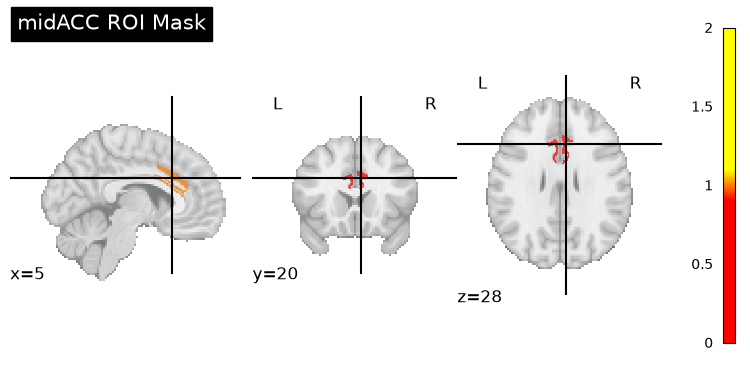

In [24]:
# Load AFNI mask
roi_img = image.load_img('./afni_pro_glm/group_results/midACC_mask.nii.gz')


# Plot ROI over mni background
plotting.plot_roi(roi_img,
                  title="midACC ROI Mask",
                  display_mode='ortho',
                  cmap='autumn', draw_cross=True)

**3. Resample the Mask to Match Functional Data:**

To ensure compatibility with the functional/statistical datasets, we resample the ROI mask to the same voxel resolution as the subject-level `stats+tlrc` files:

In [25]:
! 3dresample -master ./afni_pro_glm/sub-01.results/stats.sub-01+tlrc -input ./afni_pro_glm/group_results/midACC_mask+tlrc -prefix ./afni_pro_glm/group_results/midACC_rs+tlrc

** ERROR: output dataset name 'midACC_rs' conflicts with existing file
** ERROR: dataset NOT written to disk!
failure: cannot write dataset, exiting...


**4. Extract Contrast Values from Each Subject:**

We extract the contrast estimate for each subject by:

1. Collecting the congruent and incongruent beta sub-bricks across all subjects:

In [26]:
# clean up before building to ensure correct appending from scratch
for fname in [
    "./afni_pro_glm/group_results/Congruent_betas+tlrc.HEAD",
    "./afni_pro_glm/group_results/Congruent_betas+tlrc.BRIK",
    "./afni_pro_glm/group_results/Incongruent_betas+tlrc.HEAD",
    "./afni_pro_glm/group_results/Incongruent_betas+tlrc.BRIK",
]:
    if os.path.exists(fname):
        os.remove(fname)

subjects = [f"sub-{i:02d}" for i in range(1, 4)]
for subj in subjects:
    stats_path = f"./afni_pro_glm/{subj}.results/stats.{subj}+tlrc"
    
    if os.path.exists(f"{stats_path}.HEAD"):
        subprocess.run([
            "3dbucket", "-aglueto", "./afni_pro_glm/group_results/Congruent_betas+tlrc.HEAD", f"{stats_path}[1]"
        ])
        subprocess.run([
            "3dbucket", "-aglueto", "./afni_pro_glm/group_results/Incongruent_betas+tlrc.HEAD", f"{stats_path}[4]"
        ])
    else:
        print(f"Skipping {subj}: stats file not found")

++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
*+ WARNING: Over-writing dataset ././afni_pro_glm/group_results/Congruent_betas+tlrc.HEAD
++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
*+ WARNING: Over-writing dataset ././afni_pro_glm/group_results/Incongruent_betas+tlrc.HEAD
++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
*+ WARNING: Over-writing dataset ././afni_pro_glm/group_results/Congruent_betas+tlrc.HEAD
++ 3dbucket: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
*+ WARNING: Over-writing dataset ././afni_pro_glm/group_results/Incongruent_betas+tlrc.HEAD


This will produce 4D images:

- `Congruent_betas+tlrc` → all congruent betas across subjects

- `Incongruent_betas+tlrc` → all incongruent betas across subjects



2. Computing the subject-wise contrast *(Incongruent – Congruent)* using `3dcalc`:

In [27]:
# Create subject-wise contrast dataset (each sub-brick = Incongruent - Congruent)
! 3dcalc -a ./afni_pro_glm/group_results/Incongruent_betas+tlrc -b ./afni_pro_glm/group_results/Congruent_betas+tlrc -expr 'a-b' -prefix ./afni_pro_glm/group_results/incong_minus_cong+tlrc

++ 3dcalc: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
++ Authored by: A cast of thousands
** ERROR: output dataset name 'incong_minus_cong' conflicts with existing file
** ERROR: dataset NOT written to disk!


3. Extracting the mean contrast value within the ROI for each subject using `3dmaskave`:

In [28]:
# Extract average contrast value from ROI for each subject
! 3dmaskave -quiet -mask ./afni_pro_glm/group_results/midACC_rs+tlrc ./afni_pro_glm/group_results/incong_minus_cong+tlrc > ./afni_pro_glm/group_results/contrast_vals.txt

++ 3dmaskave: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
+++ 147 voxels survive the mask


**5. Statistical Testing:**
Finally, we load the contrast values and run a one-sample t-test to determine whether the average contrast across subjects significantly differs from zero:

In [29]:
# Load contrast values (one per subject)
contrast_vals = np.loadtxt("./afni_pro_glm/group_results/contrast_vals.txt")

# Run a one-sample t-test against 0
t_stat, p_val = ttest_1samp(contrast_vals, 0)

# Print results
print(f"Mean contrast: {np.mean(contrast_vals):.4f}")
print(f"t = {t_stat:.4f}, p = {p_val:.4f}")

Mean contrast: 0.1796
t = 2.2511, p = 0.1532


##### ✅ Interpretation

This provides a simple but interpretable ROI-based statistical test focused on the `Incongruent - Congruent` contrast in the midACC. This result indicates that:

- **On average**, the contrast *Incongruent - Congruent* is **positive** within the **mid anterior cingulate cortex (midACC)** ROI.  
- The difference is **not statistically significant** at the **α = 0.05** level (*p* = 0.153) with only 3 subjects. 
- The direction of the effect is consistent with the expected result — greater midACC activation during Incongruent compared to Congruent trials.
- The lack of significance is expected given the very small sample size of 3 subjects — this result is for demonstration purposes only.

### 4.2 ROI Analysis Using a Spherical Mask

To complement the atlas-based ROI analysis, we can also define a **spherical ROI** centered on a coordinate of interest. This can be useful for hypothesis-driven analyses targeting specific anatomical or functional peaks.

**1. Define the sphere:**
   - A 5mm radius sphere is created around the coordinate *(0, 20, 44)* using AFNI's `3dUndump`.
   - The sphere is aligned to the grid of the functional data via the `-master` option.

   ```bash
   echo "0 20 44" | 3dUndump -orient LPI -srad 5 -master Incongruent_betas+tlrc -prefix ConflictROI+tlrc -xyz -
   ```


In [30]:
# This script creates a 5mm sphere around a coordinate
# Change the x,y,z, coordinates on the left side to select a different peak
# Radius size can be changed with the -srad option

! echo "0 20 44" | 3dUndump -orient LPI -srad 5 -master ./afni_pro_glm/group_results/Incongruent_betas+tlrc -prefix ./afni_pro_glm/group_results/ConflictROI+tlrc -xyz -

++ 3dUndump: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
++ Starting to fill via -xyz coordinates
++ Total number of voxels filled = 19
** ERROR: output dataset name 'ConflictROI' conflicts with existing file
** ERROR: dataset NOT written to disk!
++ Wrote out dataset ././afni_pro_glm/group_results/ConflictROI_AA1+tlrc.BRIK


**2. Extract ROI contrast values:**


- The average `Incongruent - Congruent` contrast value will be computed for each subject using `3dmaskave`:

In [31]:
! 3dmaskave -quiet -mask ./afni_pro_glm/group_results/ConflictROI+tlrc ./afni_pro_glm/group_results/incong_minus_cong+tlrc > ./afni_pro_glm/group_results/contrast_vals_sphere.txt

++ 3dmaskave: AFNI version=AFNI_25.2.03 (Jul  4 2025) [64-bit]
+++ 19 voxels survive the mask


**3. Statistical test:**

- A one-sample t-test can be performed to determine whether the contrast values within the sphere significantly differ from zero.

In [32]:
# Load contrast values (one per subject)
contrast_vals_sphere = np.loadtxt("./afni_pro_glm/group_results/contrast_vals_sphere.txt")

# Run a one-sample t-test against 0
t_stat_sphere, p_val_sphere = ttest_1samp(contrast_vals_sphere, 0)

# Print results
print(f"Mean contrast: {np.mean(contrast_vals_sphere):.4f}")
print(f"t = {t_stat_sphere:.4f}, p = {p_val_sphere:.4f}")

Mean contrast: 0.2386
t = 1.8883, p = 0.1996


#### ✅ Interpretation of Sphere ROI Results

- The mean contrast value for *Incongruent-Congruent* in the spherical ROI is **0.2386**.
- The one-sample t-test does not shows a significant effect at the **α = 0.05** level:  
  *t*(2) = 1.8883, *p* = 0.1996.
- The direction of the effect remains consistent with the expected result — greater activation during Incongruent compared to Congruent trials — but the small sample size of 3 subjects is insufficient to reach statistical significance.
- This result is for **demonstration purposes only**.

#### Dependencies in Jupyter/Python
- Using the package [watermark](https://github.com/rasbt/watermark) to document system environment and software versions used in this notebook, alongside the Neurodesktop version extracted from the `JUPYTER_IMAGE` or `NEURODESKTOP_VERSION` environment variables.

In [33]:
import os

%load_ext watermark

%watermark
%watermark --iversions

neurodesktop_version = (
    os.environ.get('JUPYTER_IMAGE', '').split(':')[-1] or
    os.environ.get('NEURODESKTOP_VERSION', 'unknown')
)

print(f"Neurodesktop version: {neurodesktop_version}")

Last updated: 2026-10-08T17:01:41.132100+00:00

Python implementation: CPython
Python version       : 3.13.15
IPython version      : 9.17.1

Compiler    : GCC 15.3.0
OS          : Linux
Release     : 6.8.0-111-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit

IPython   : 9.17.1
ipyniivue : 2.4.4
matplotlib: 3.11.2
nibabel   : 5.4.2
nilearn   : 0.13.1
numpy     : 2.5.3
scipy     : 1.18.1
tqdm      : 4.70.1

Neurodesktop version: 2026-10-05
